In [20]:
import numpy as np
import pandas as pd

In [21]:
df= pd.read_csv('Placement_Data_Full_Class.csv')

In [22]:
df.head()

,Sno,Gender,10th %,SSC Board,12th %,HSC Board,12th Stream,Degree %,Degree stream,Work exp,specialisation,Mba %,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,Mkt&Fin,55.50,Placed,425000.0


In [23]:
df.shape

(215, 14)

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sno             215 non-null    int64  
 1   Gender          215 non-null    object 
 2   10th %          215 non-null    float64
 3   SSC Board       215 non-null    object 
 4   12th %          215 non-null    float64
 5   HSC Board       215 non-null    object 
 6   12th Stream     215 non-null    object 
 7   Degree %        215 non-null    float64
 8   Degree stream   215 non-null    object 
 9   Work exp        215 non-null    object 
 10  specialisation  215 non-null    object 
 11  Mba %           215 non-null    float64
 12  status          215 non-null    object 
 13  salary          148 non-null    float64
dtypes: float64(5), int64(1), object(8)
memory usage: 23.6+ KB


In [25]:
## Preprocessing + EDA + Feature Selection

In [26]:
df.isnull() 

,Sno,Gender,10th %,SSC Board,12th %,HSC Board,12th Stream,Degree %,Degree stream,Work exp,specialisation,Mba %,status,salary
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,False,False,False,False,False,False,False,False,False,False,False,False,False,False
211,False,False,False,False,False,False,False,False,False,False,False,False,False,False
212,False,False,False,False,False,False,False,False,False,False,False,False,False,False
213,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [27]:
df.isnull().sum()

Sno                0
Gender             0
10th %             0
SSC Board          0
12th %             0
HSC Board          0
12th Stream        0
Degree %           0
Degree stream      0
Work exp           0
specialisation     0
Mba %              0
status             0
salary            67
dtype: int64

In [28]:
df.isnull().sum(axis=1)

0      0
1      0
2      0
3      1
4      0
      ..
210    0
211    0
212    0
213    0
214    1
Length: 215, dtype: int64

In [29]:
df= df.iloc[:,1:]

In [30]:
df.head()

,Gender,10th %,SSC Board,12th %,HSC Board,12th Stream,Degree %,Degree stream,Work exp,specialisation,Mba %,status,salary
0,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,Mkt&HR,58.80,Placed,270000.0
1,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,Mkt&Fin,66.28,Placed,200000.0
2,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,Mkt&Fin,57.80,Placed,250000.0
3,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,Mkt&HR,59.43,Not Placed,NaN
4,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,Mkt&Fin,55.50,Placed,425000.0


In [31]:
df=df.drop(columns='salary')

In [32]:
df.head()

,Gender,10th %,SSC Board,12th %,HSC Board,12th Stream,Degree %,Degree stream,Work exp,specialisation,Mba %,status
0,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,Mkt&HR,58.80,Placed
1,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,Mkt&Fin,66.28,Placed
2,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,Mkt&Fin,57.80,Placed
3,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,Mkt&HR,59.43,Not Placed
4,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,Mkt&Fin,55.50,Placed


In [33]:
import matplotlib.pyplot as plt 

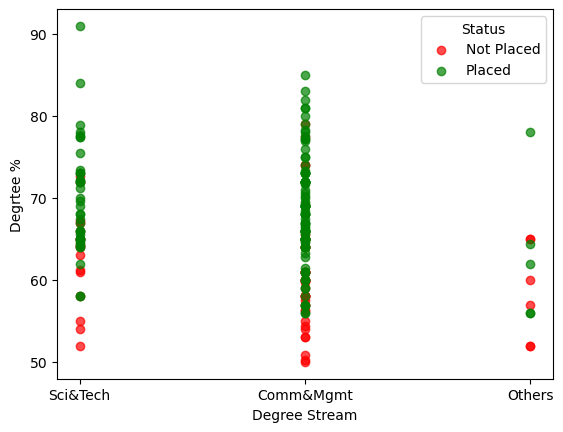

In [34]:
colors= {'Placed':'Green','Not Placed':'red'}

for status, group in df.groupby('status'):
    plt.scatter(group['Degree stream'],
                group['Degree %'],
                label=status, 
                color=colors[status],
                alpha=0.7)

plt.xlabel('Degree Stream')
plt.ylabel('Degrtee %')
plt.legend(title= "Status")
plt.show()
        

In [35]:
pd.crosstab(df['Work exp'],df['status'].plot(kind='bar'))
plt.xlabel('Work exp ')
plt.ylabel('status')
plt.title("Work experience affecting the placement")
plt.show()

TypeError: no numeric data to plot

In [36]:
count=pd.crosstab(df['Work exp'],df['status'])

In [37]:
count

status,Not Placed,Placed
Work exp,,
No,57,84
Yes,10,64


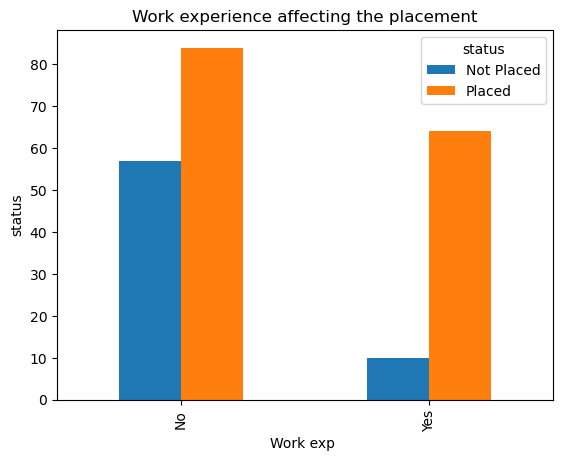

In [38]:
count.plot(kind='bar')
plt.xlabel('Work exp ')
plt.ylabel('status')
plt.title("Work experience affecting the placement")
plt.show()

In [39]:
 #Extracting input and output columns 
X= df.iloc[:,0:11]
X.head()

,Gender,10th %,SSC Board,12th %,HSC Board,12th Stream,Degree %,Degree stream,Work exp,specialisation,Mba %
0,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,Mkt&HR,58.80
1,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,Mkt&Fin,66.28
2,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,Mkt&Fin,57.80
3,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,Mkt&HR,59.43
4,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,Mkt&Fin,55.50


In [40]:
Y= df['status']
Y.head()
Y.shape 

(215,)

In [41]:
#Train Test Split 
from sklearn.model_selection import train_test_split


In [42]:
X_train, X_test, Y_train, Y_test=train_test_split(X,Y,test_size=0.1)

In [43]:
X_train

,Gender,10th %,SSC Board,12th %,HSC Board,12th Stream,Degree %,Degree stream,Work exp,specialisation,Mba %
136,F,47.00,Central,59.0,Central,Arts,64.00,Comm&Mgmt,No,Mkt&Fin,61.58
70,M,82.00,Others,61.0,Others,Science,62.00,Sci&Tech,No,Mkt&Fin,65.45
23,F,77.40,Others,60.0,Others,Science,64.74,Sci&Tech,Yes,Mkt&Fin,63.62
30,F,64.00,Central,73.5,Central,Commerce,73.00,Comm&Mgmt,No,Mkt&HR,56.70
128,M,80.40,Central,73.4,Central,Science,77.72,Sci&Tech,Yes,Mkt&HR,76.26
...,...,...,...,...,...,...,...,...,...,...,...
88,F,66.00,Central,62.0,Central,Commerce,73.00,Comm&Mgmt,No,Mkt&HR,64.36
208,F,43.00,Central,60.0,Others,Science,65.00,Comm&Mgmt,No,Mkt&HR,62.92
6,F,46.00,Others,49.2,Others,Commerce,79.00,Comm&Mgmt,No,Mkt&Fin,53.29
67,M,80.92,Others,78.5,Others,Commerce,67.00,Comm&Mgmt,No,Mkt&Fin,60.99


In [44]:
X_test

,Gender,10th %,SSC Board,12th %,HSC Board,12th Stream,Degree %,Degree stream,Work exp,specialisation,Mba %
196,M,72.00,Others,63.00,Others,Science,77.50,Sci&Tech,Yes,Mkt&Fin,54.48
52,F,40.89,Others,45.83,Others,Commerce,53.00,Comm&Mgmt,No,Mkt&HR,65.49
125,F,84.00,Central,73.00,Central,Commerce,73.00,Comm&Mgmt,No,Mkt&Fin,73.33
92,F,60.23,Central,69.00,Central,Science,66.00,Comm&Mgmt,No,Mkt&Fin,59.47
79,F,69.00,Central,62.00,Central,Science,66.00,Sci&Tech,No,Mkt&HR,67.99
153,M,49.00,Others,59.00,Others,Science,65.00,Sci&Tech,Yes,Mkt&Fin,62.48
46,F,70.89,Others,71.98,Others,Science,65.60,Comm&Mgmt,No,Mkt&HR,71.63
181,M,62.00,Central,60.33,Others,Science,64.21,Sci&Tech,No,Mkt&HR,60.02
100,F,45.00,Others,57.00,Others,Commerce,58.00,Comm&Mgmt,Yes,Mkt&HR,64.95
195,M,66.00,Central,76.00,Central,Commerce,72.00,Comm&Mgmt,Yes,Mkt&HR,58.95


In [45]:
Y_train

136    Not Placed
70         Placed
23         Placed
30         Placed
128        Placed
          ...    
88         Placed
208    Not Placed
6      Not Placed
67         Placed
160        Placed
Name: status, Length: 193, dtype: object

In [46]:
Y_test

196        Placed
52     Not Placed
125        Placed
92         Placed
79     Not Placed
153        Placed
46     Not Placed
181    Not Placed
100    Not Placed
195        Placed
26         Placed
121        Placed
145        Placed
104        Placed
95         Placed
61         Placed
197        Placed
114        Placed
212        Placed
170    Not Placed
134        Placed
131        Placed
Name: status, dtype: object

In [47]:
#As the categorical input data cannot be labeled directly , We need to first encode those data and then merge into numerical data ..

In [48]:
from sklearn.preprocessing import OneHotEncoder

In [49]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)


categorical_cols= ['Gender',
                 'SSC Board',
                 'HSC Board',
                 '12th Stream',
                 'Degree stream',
                 'Work exp',
                 'specialisation']

X_train_cat= encoder.fit_transform(X_train[categorical_cols])
X_test_cat= encoder.transform(X_test[categorical_cols])

In [50]:
#Now , we are merging the encoded categorical with the numerical values in the test set..

import numpy as np

numeric_cols=['10th %',
             '12th %',
             'Degree %',
             'Mba %']
X_train_final= np.hstack([X_train[numeric_cols].values,
                         X_train_cat])

X_test_final=np.hstack([X_test[numeric_cols].values,
                      X_test_cat])

In [51]:
#Scaling the data from negative to postitive

In [52]:
from sklearn.preprocessing import StandardScaler


In [53]:
scaler= StandardScaler()

In [54]:
X_train_final= scaler.fit_transform(X_train_final)

In [55]:
X_train_final

array([[-1.89745063, -0.66327379, -0.30193495, ..., -0.69614322,
         0.86864576, -0.86864576],
       [ 1.39078489, -0.48133929, -0.57517284, ..., -0.69614322,
         0.86864576, -0.86864576],
       [ 0.9586168 , -0.57230654, -0.20083693, ...,  1.43648601,
         0.86864576, -0.86864576],
       ...,
       [-1.99140022, -1.55475282,  1.74734925, ..., -0.69614322,
         0.86864576, -0.86864576],
       [ 1.28931934,  1.11058756,  0.10792189, ..., -0.69614322,
         0.86864576, -0.86864576],
       [ 1.86053282,  0.70123494, -0.165316  , ...,  1.43648601,
        -1.15121727,  1.15121727]], shape=(193, 20))

In [56]:
X_test_final=scaler.transform(X_test_final)
X_test_final

array([[ 0.45128903, -0.29940479,  1.54242083, -1.30527357, -0.71260964,
         0.71260964, -1.09232862,  1.09232862, -0.83245568,  0.83245568,
        -0.24584459, -1.0697871 ,  1.20126516, -1.45358289, -0.23376229,
         1.64667497, -1.43648601,  1.43648601,  0.86864576, -0.86864576],
       [-2.4714826 , -1.86131245, -1.80474336,  0.58204005,  1.40329283,
        -1.40329283, -1.09232862,  1.09232862, -0.83245568,  0.83245568,
        -0.24584459,  0.93476543, -0.83245568,  0.68795526, -0.23376229,
        -0.60728439,  0.69614322, -0.69614322, -1.15121727,  1.15121727],
       [ 1.57868407,  0.61026769,  0.92763557,  1.92595819,  1.40329283,
        -1.40329283,  0.91547542, -0.91547542,  1.20126516, -1.20126516,
        -0.24584459,  0.93476543, -0.83245568,  0.68795526, -0.23376229,
        -0.60728439,  0.69614322, -0.69614322,  0.86864576, -0.86864576],
       [-0.6544976 ,  0.2463987 , -0.02869706, -0.4498971 ,  1.40329283,
        -1.40329283,  0.91547542, -0.91547542,  

In [57]:
from sklearn.linear_model import LogisticRegression

In [58]:
clf= LogisticRegression()


In [59]:
#Model training
clf.fit(X_train_final, Y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [60]:

Y_predicted =clf.predict(X_test_final)

In [61]:
Y_test

196        Placed
52     Not Placed
125        Placed
92         Placed
79     Not Placed
153        Placed
46     Not Placed
181    Not Placed
100    Not Placed
195        Placed
26         Placed
121        Placed
145        Placed
104        Placed
95         Placed
61         Placed
197        Placed
114        Placed
212        Placed
170    Not Placed
134        Placed
131        Placed
Name: status, dtype: object

In [62]:
from sklearn.metrics import accuracy_score


In [63]:
accuracy_score(Y_test,Y_predicted)

0.8636363636363636

In [66]:
print("X_train_final" in globals())

True


In [69]:
import pickle 

In [70]:
pickle.dump(clf,open('model.pkl','wb'))